# One custom model, three environments

Train a small **ResidualWorldModel** on **Maze**, **KeyDoor**, and **Sokoban**, and compare it with the library's **LeWM** baseline. Both use the library's CEM planner and experiment runner. Replace one factory to try another model.

These are our own puzzle implementations with RGB observations. Each section includes the initial environment, **GT** target, a verified reference solution, measured results, and episode GIFs. Reference solutions are displayed separately and never used as training actions.

Run from this directory with `pip install -e "../..[notebooks]"`. A GPU is optional; the runner selects CUDA when available.

In [1]:
from datetime import datetime, timezone
from functools import partial
from math import prod
from pathlib import Path

import torch
from IPython.display import Markdown, display
from torch import nn
from torch.nn import functional as F

from torch_world import metrics, plots
from torch_world.benchmarks import (
    lewm_baseline,
    observation_encoder,
    run_experiment,
    show_results,
    write_summary,
)
from torch_world.envs import KeyDoor, Maze, Sokoban
from torch_world.models import WorldModel
from torch_world.planning import CEM

## Custom model

The encoder maps each RGB frame to 32 features. A residual MLP predicts the next features from the current features and action; a decoder reconstructs RGB observations. Training combines reconstruction, next-frame prediction, and latent dynamics losses. Reconstruction gives the representation an observation-level learning signal. A small batch-variance penalty discourages constant features, which can otherwise fit these nearly static images.

The interface is `encode(B, T, C, H, W) → (B, T, 32)`, `predict(B, T, 32; B, T, A) → (B, T, 32)`, and `forward(observations, actions)["loss"]`. `WorldModel` supplies autoregressive rollout and terminal goal cost; CEM uses those methods without knowing the architecture. This example uses `history=1`. The `partial` factory exposes model hyperparameters without rewriting the experiment; its bound arguments are saved automatically.

In [2]:
class ResidualWorldModel(WorldModel):
    """An RGB autoencoder with action-conditioned residual dynamics."""

    history = 1

    def __init__(self, observation_shape, action_dim, hidden_dim=128, variance_weight=0.1):
        super().__init__()
        self.observation_shape = observation_shape
        self.variance_weight = variance_weight
        self.encoder = observation_encoder(observation_shape)
        self.dynamics = nn.Sequential(nn.Linear(32 + action_dim, hidden_dim), nn.GELU(), nn.Linear(hidden_dim, 32))
        self.decoder = nn.Sequential(
            nn.Linear(32, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, prod(observation_shape)),
            nn.Sigmoid(),
        )

    def encode(self, observations):
        batch, time = observations.shape[:2]
        return self.encoder(observations.flatten(0, 1)).reshape(batch, time, 32)

    def predict(self, latents, actions):
        return latents + self.dynamics(torch.cat((latents, actions), dim=-1))

    def decode(self, latents):
        return self.decoder(latents).reshape(*latents.shape[:2], *self.observation_shape)

    def forward(self, observations, actions):
        latents = self.encode(observations)
        predicted = self.predict(latents[:, :-1], actions[:, :-1])
        reconstruction = F.mse_loss(self.decode(latents), observations)
        prediction = F.mse_loss(self.decode(predicted), observations[:, 1:])
        dynamics = F.mse_loss(predicted, latents[:, 1:].detach())
        spread = (latents.flatten(0, 1).var(dim=0, unbiased=False) + 1e-4).sqrt()
        variance = F.relu(1 - spread).mean()
        return {"loss": reconstruction + prediction + dynamics + self.variance_weight * variance}


model_factory = partial(ResidualWorldModel, hidden_dim=128, variance_weight=0.1)


def planner_factory(action_dim):
    return CEM(8, action_dim, num_samples=96, num_elites=12, iterations=3, bounds=(-1, 1))

## Shared experiment

Protocol `one-step-world-model-v2` samples continuous controls, including waits, using the same action decoding as the environment. Each model receives the same 2,048 training pairs, disjoint held-out starting states, 400 updates, and four evaluation seeds with a 60-step budget. The optimizer, data collection, scoring, and persistence/random controls live in `run_experiment`. Each model is trained separately for each environment.

This is a small integration experiment, not evidence of generalization or a tuned benchmark. The four evaluation seeds vary policy randomness on one fixed level. Latent MSE and training-loss scales differ between models; compare task success and final distance across models.

Each notebook execution creates a campaign directory. Runs contain configuration, per-seed scores, training history, episodes, GT, GIFs, and checksums; the final CSV has one row per run/policy. The custom model source is defined above; trained weights are not saved by this runner.

In [3]:
SEED, UPDATES = 7, 400
CAMPAIGN = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
OUTPUT_DIR = Path("runs/custom_model_three_envs") / CAMPAIGN
MODEL_FACTORIES = {"LeWM": lewm_baseline, "ResidualWorldModel": model_factory}
results = []


def compare_models(world):
    world.show_env()
    display(Markdown("**GT reference solution** — verified environment actions, not a model rollout."))
    world.show_success()
    runs = []
    for name, factory in MODEL_FACTORIES.items():
        display(Markdown(f"### {name}"))
        result = run_experiment(
            world,
            model_factory=factory,
            planner_factory=planner_factory,
            seed=SEED,
            updates=UPDATES,
            samples=2048,
            evaluation_seeds=4,
            evaluation_steps=60,
            output_dir=OUTPUT_DIR,
            model_config={"recipe": name, "source": "custom_model_three_envs.ipynb"},
        )
        show_results(result)
        print("Saved run:", result["run_dir"])
        runs.append(result)
    return runs

## 1. Maze

Navigate around walls to reach the goal. This tests multi-step routing; moving directly toward the target can lead to a dead end.

**Maze-v0 · torch** — Route around walls and dead ends. 2 normalized action components in [-1, 1].

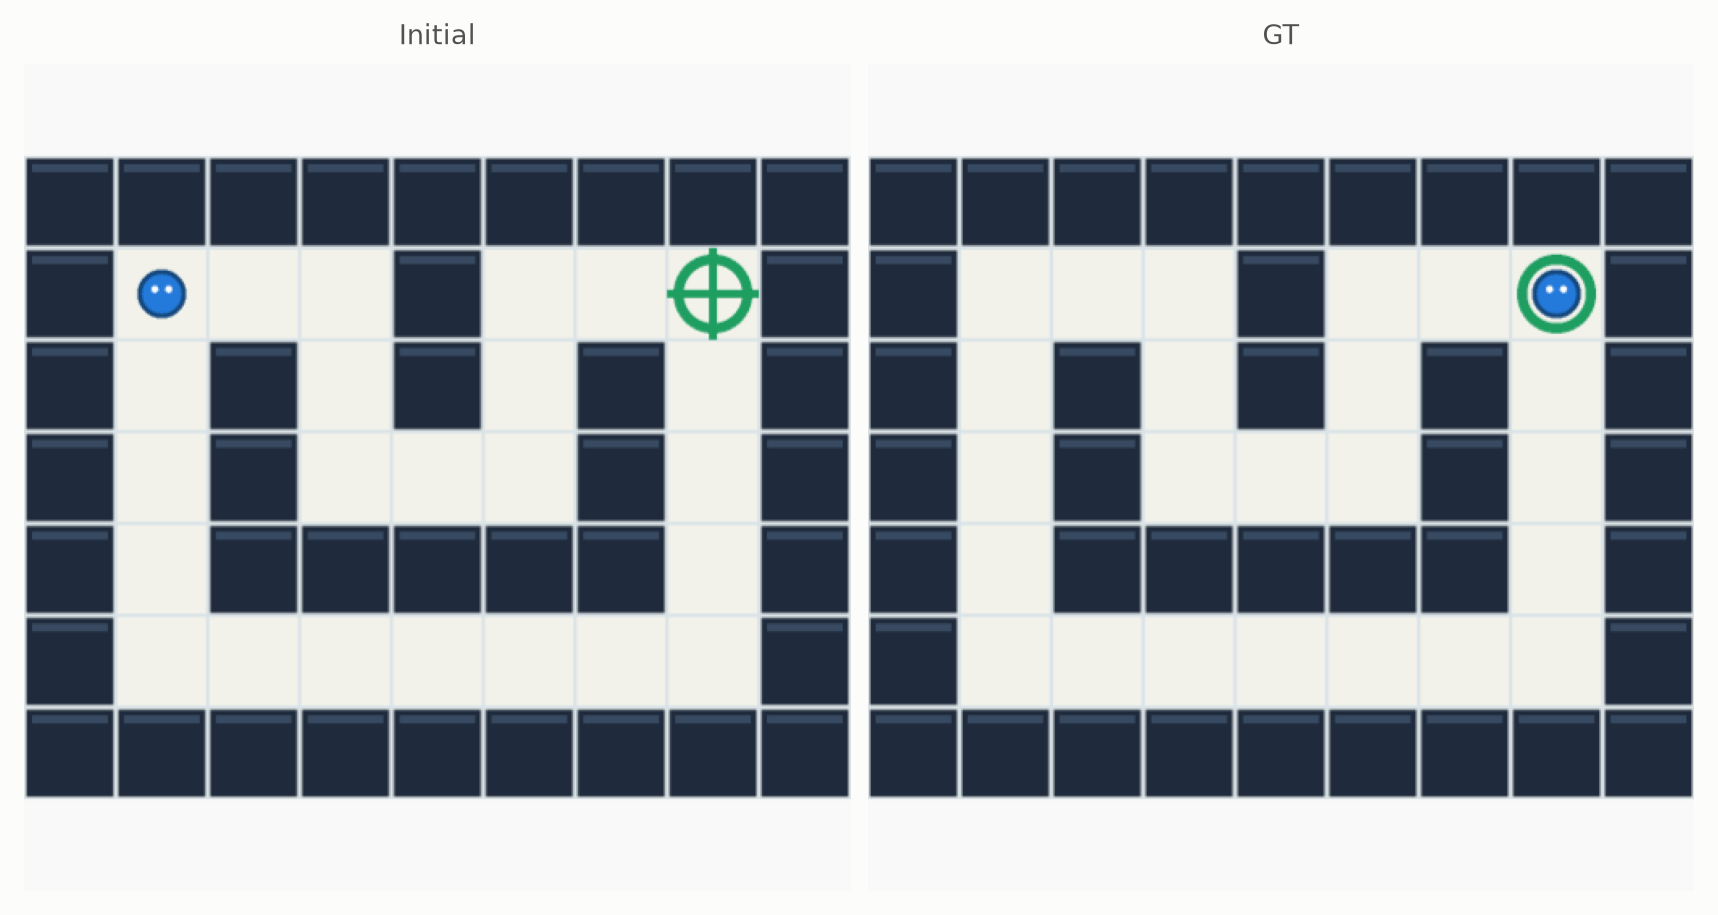

**GT reference solution** — verified environment actions, not a model rollout.

**Maze-v0** — verified reference episode; separate from model evaluation.

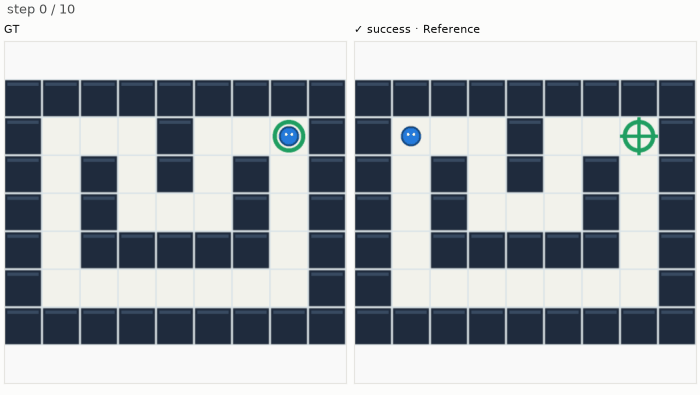

Static preview of the recorded episode. Rerun this cell to view the animation.

### LeWM

**Maze-v0 · LeWM** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 32.3 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 6324.5020 |
| Persistence | 0.1517 |

Latent standard deviation: **0.707**. Latent errors are comparable within this model; their scale differs between models.

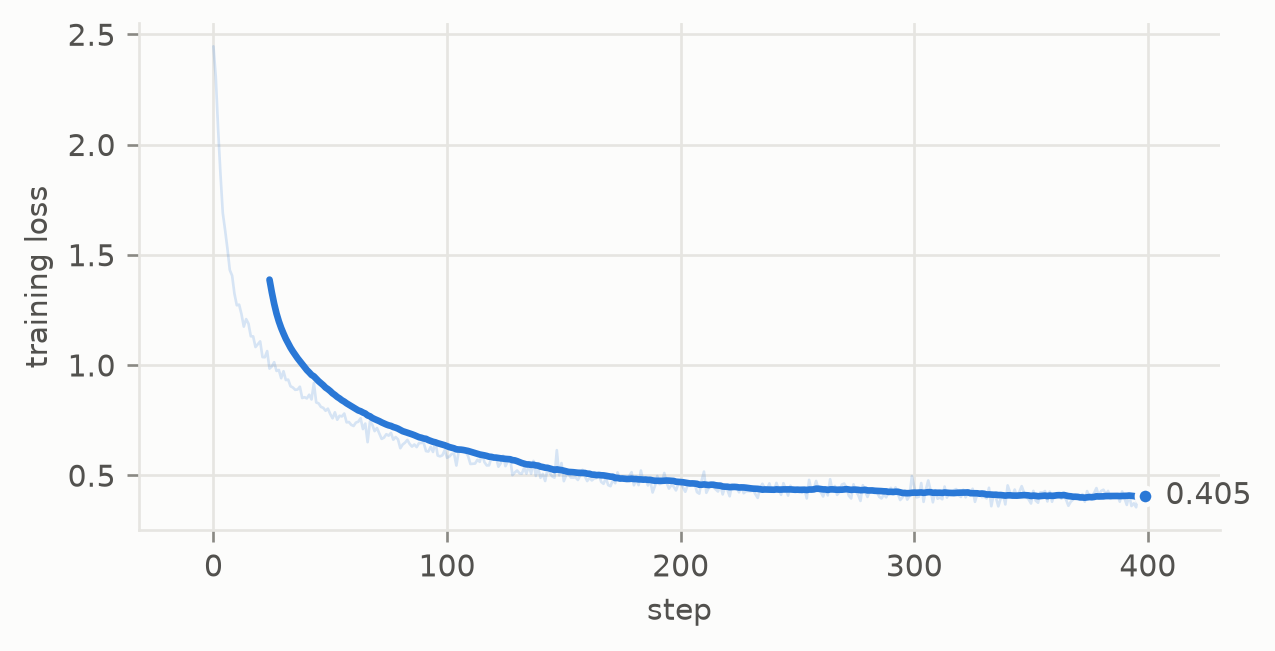

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 49%] | 60.0 | 5.500 |
| random | 0% [0%, 49%] | 60.0 | 7.500 |

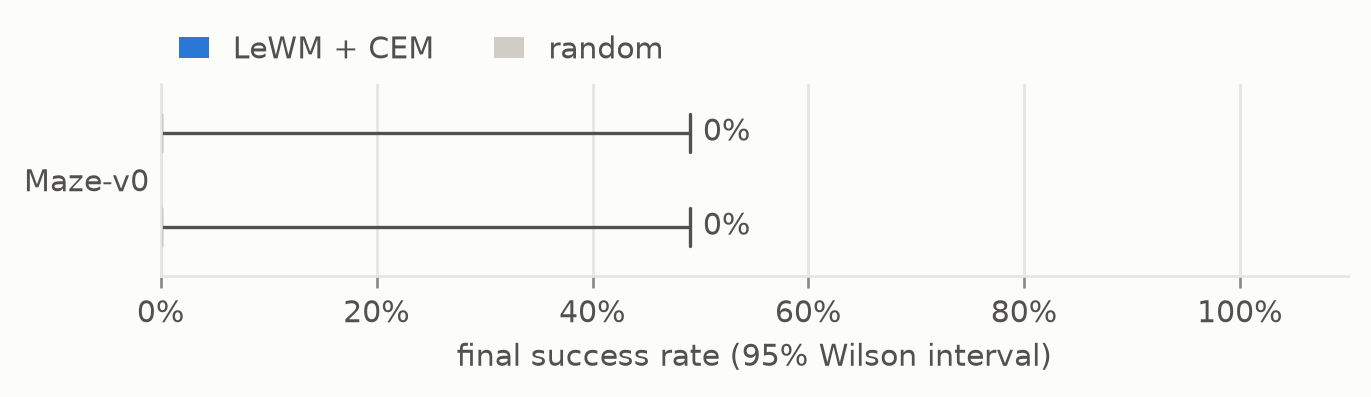

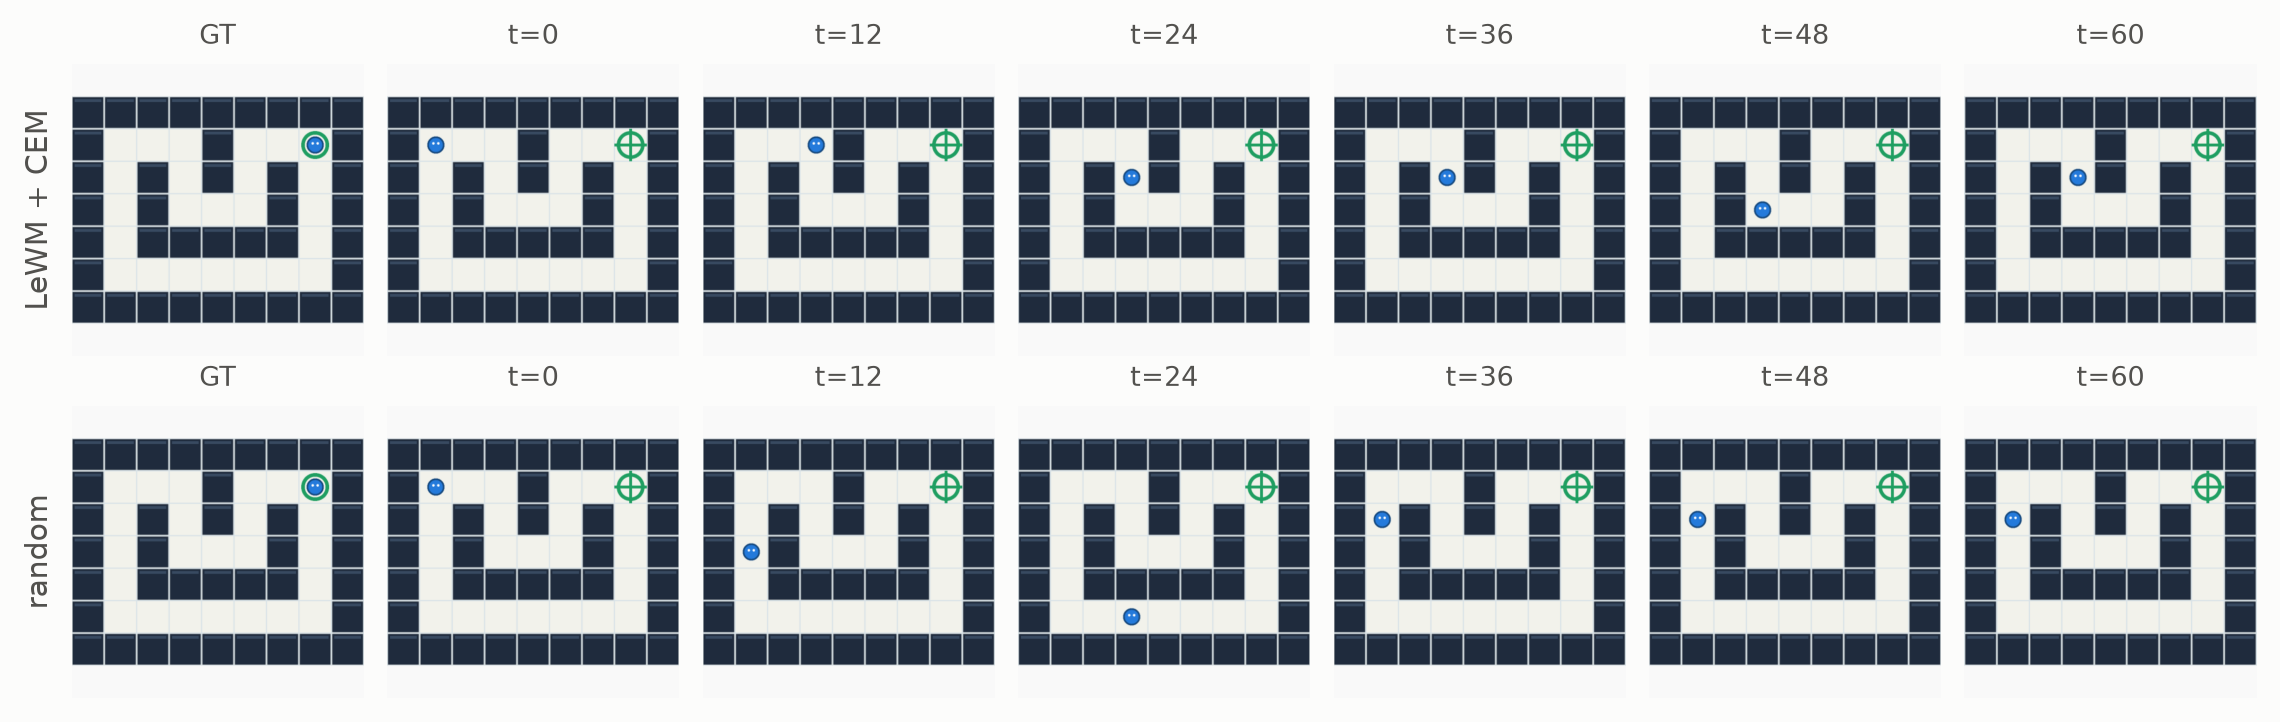

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

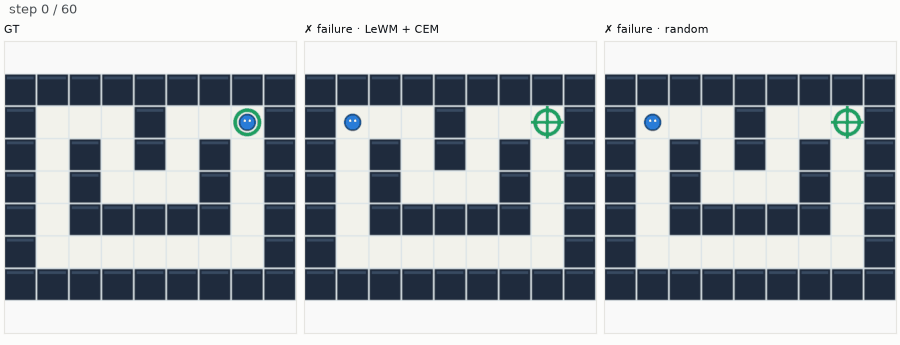

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/custom_model_three_envs/20261015T115501476827Z/Maze-v0/LeWM/20261015T115536421346Z-67dac4f9


### ResidualWorldModel

**Maze-v0 · ResidualWorldModel** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 26.4 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| ResidualWorldModel | 0.0004 |
| Persistence | 0.0000 |

Latent standard deviation: **0.002**. Latent errors are comparable within this model; their scale differs between models.

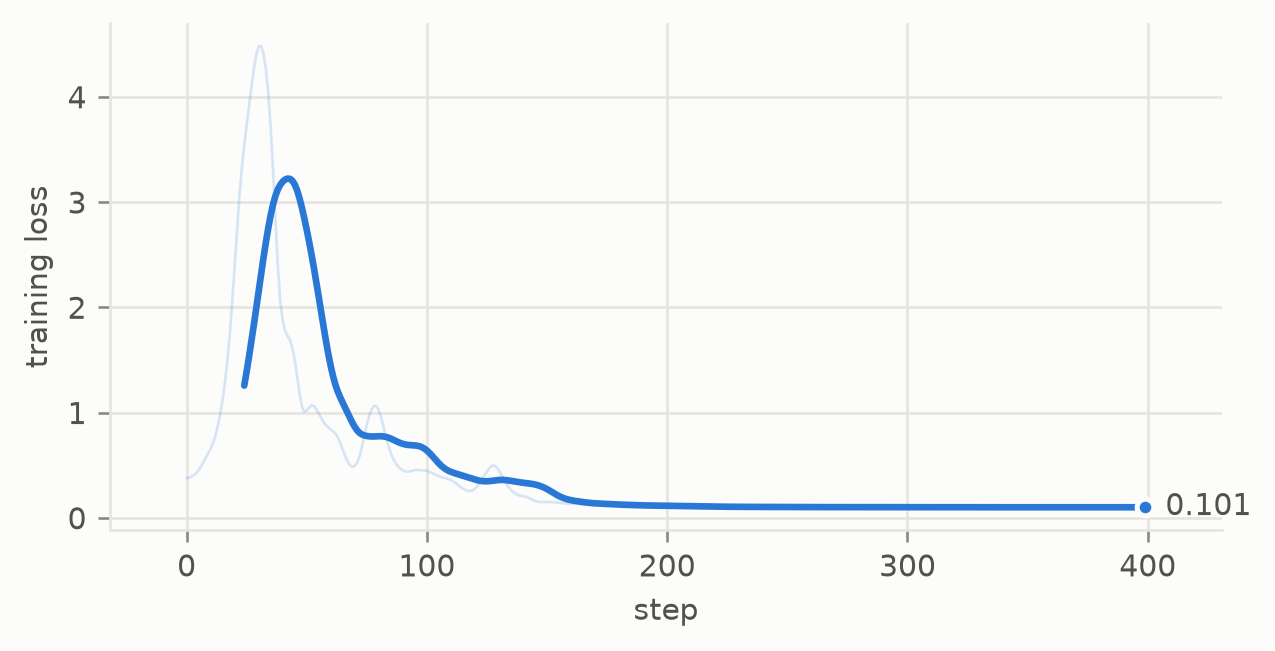

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| ResidualWorldModel + CEM | 0% [0%, 49%] | 60.0 | 10.000 |
| random | 0% [0%, 49%] | 60.0 | 7.500 |

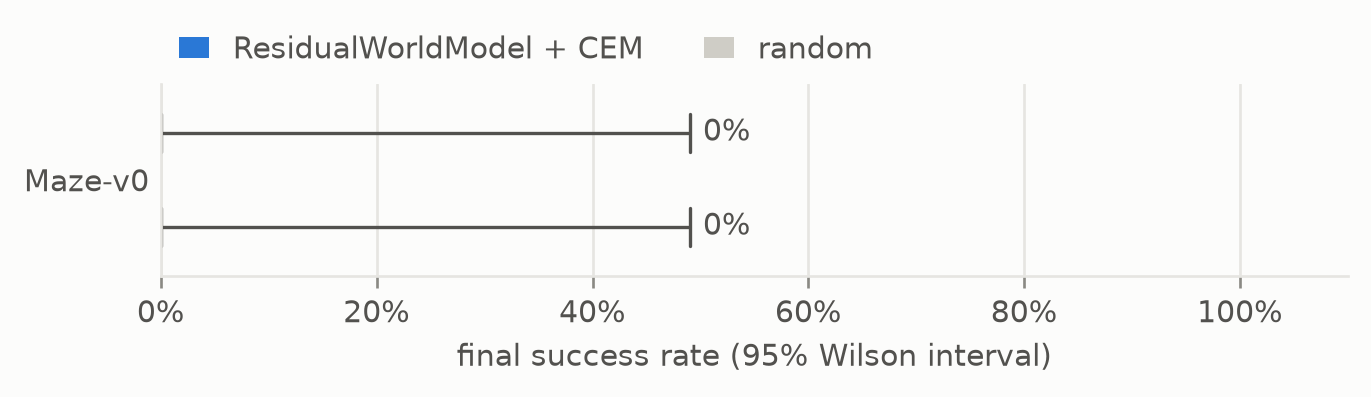

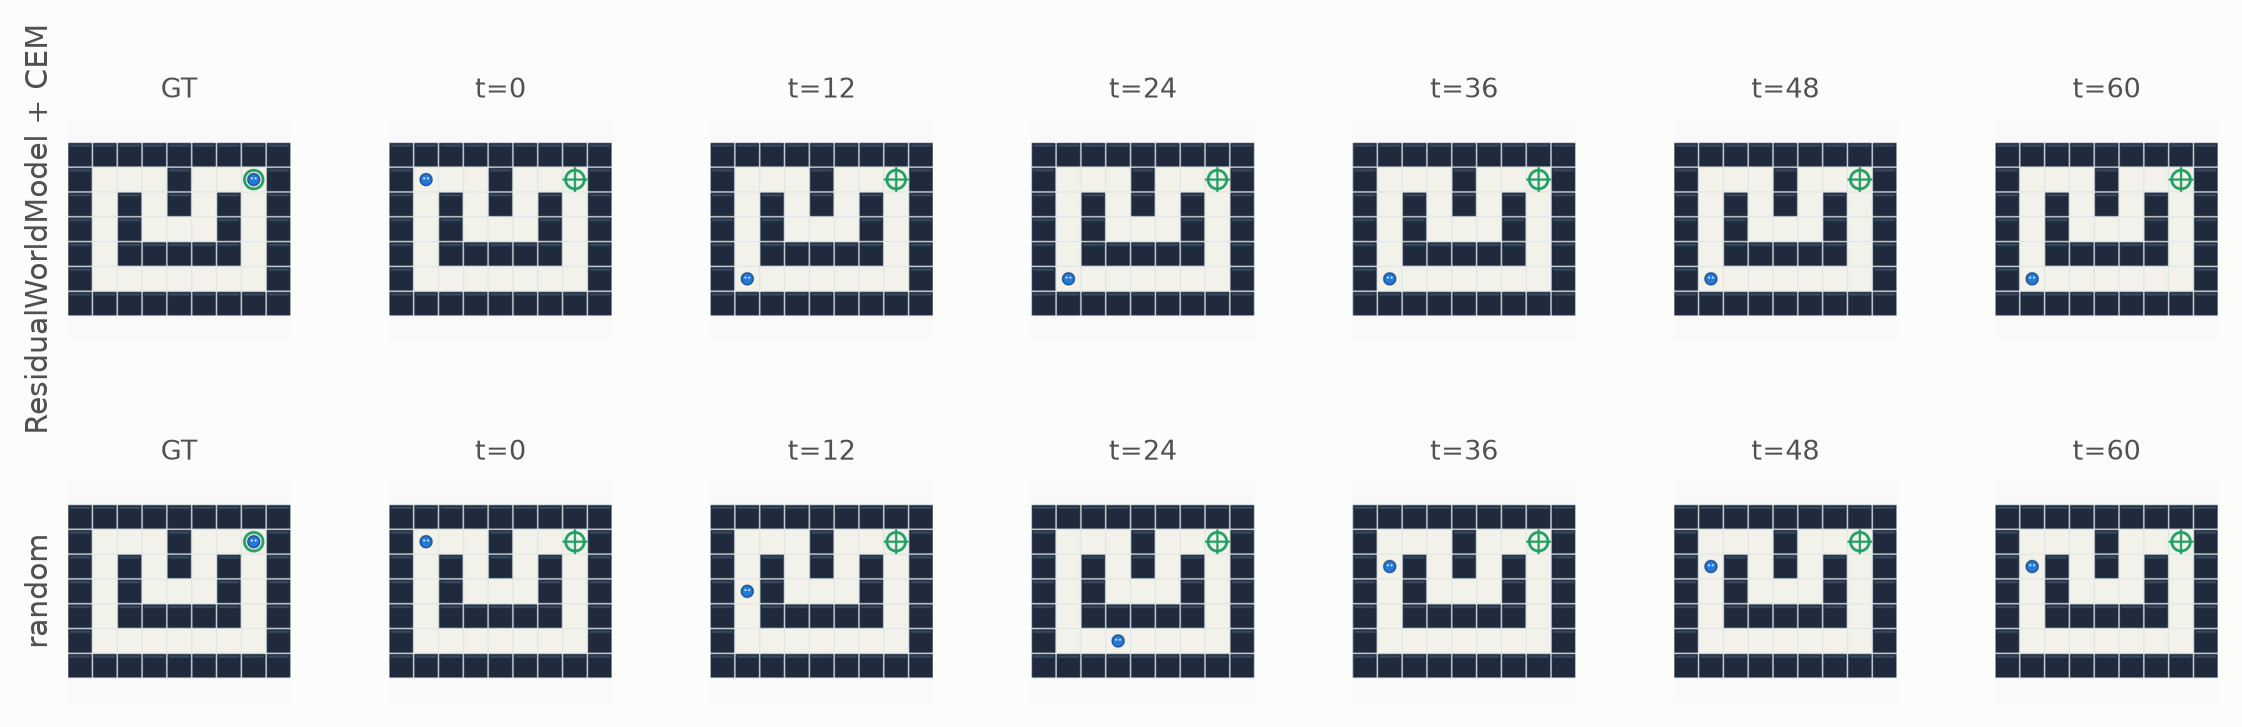

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

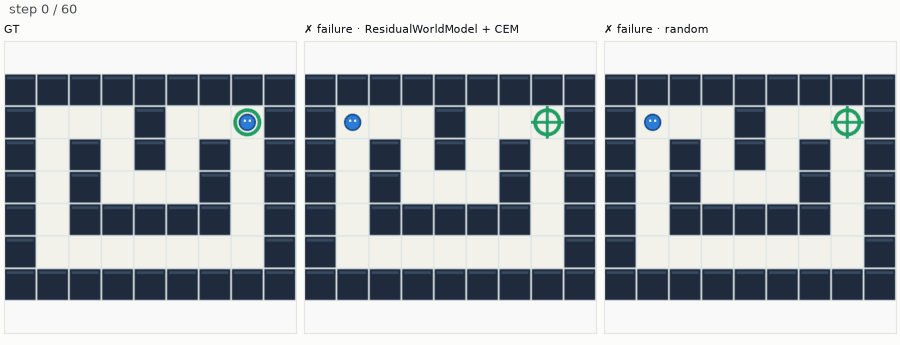

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/custom_model_three_envs/20261015T115501476827Z/Maze-v0/ResidualWorldModel/20261015T115617582484Z-36b6f34a


In [4]:
with Maze(quality="high") as world:
    results.extend(compare_models(world))

## 2. KeyDoor

Collect the key, unlock the door, and reach the goal. The useful action depends on inventory and door state, requiring a sequence of subgoals.

**KeyDoor-v0 · torch** — Collect a key before crossing a locked door. 2 normalized action components in [-1, 1].

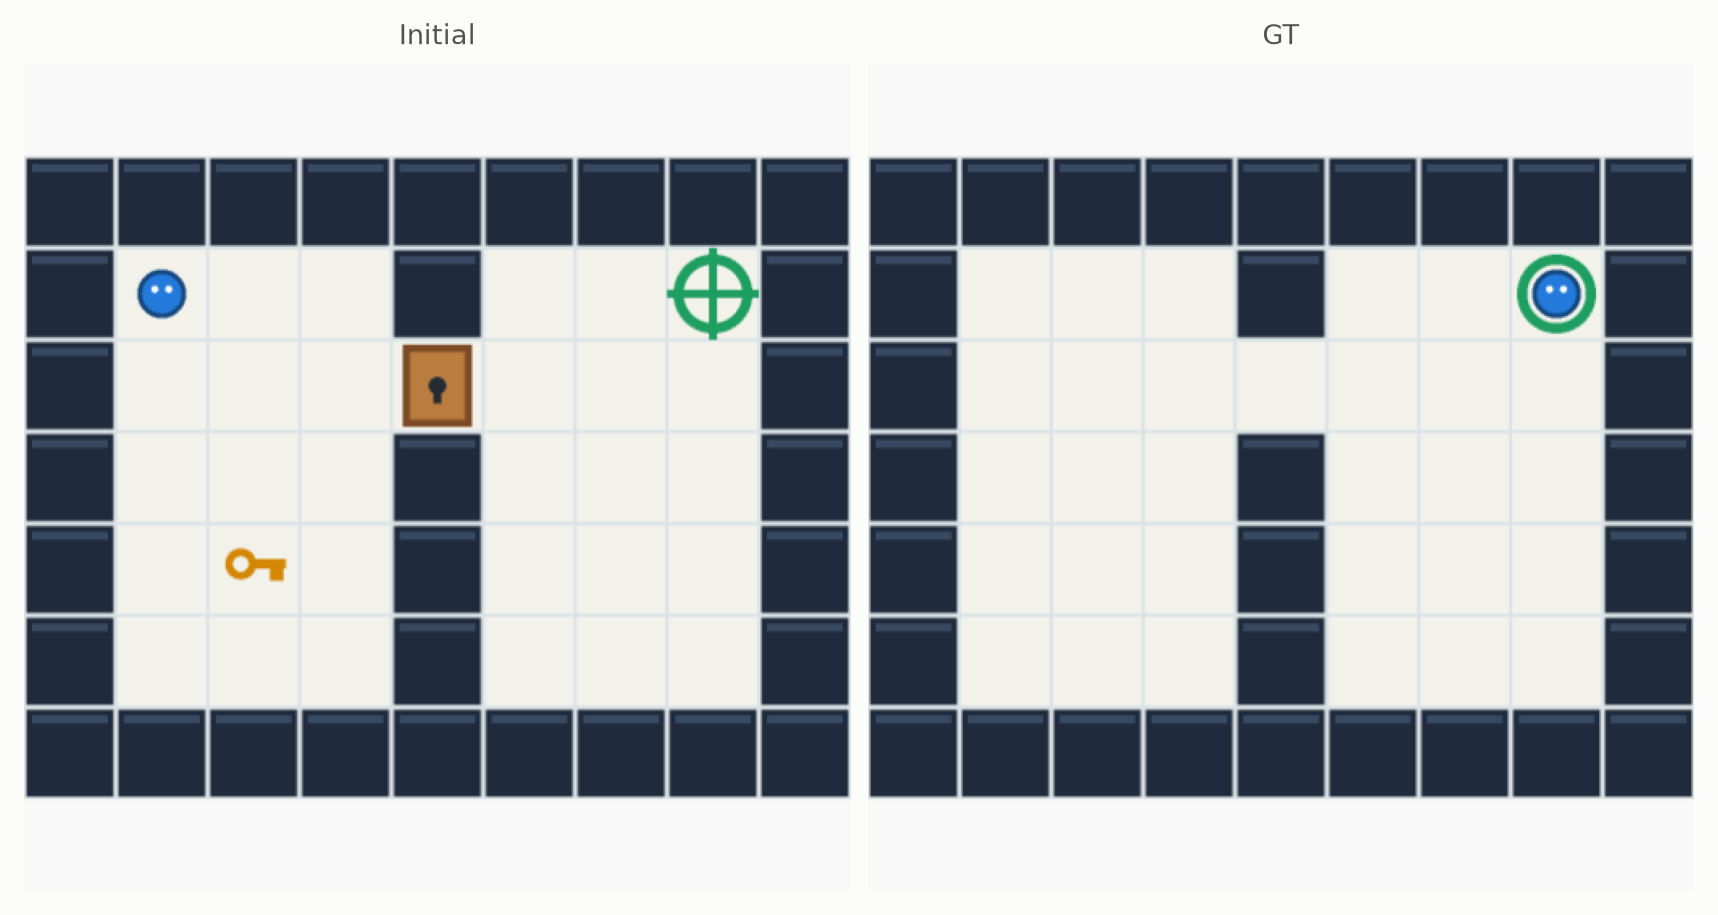

**GT reference solution** — verified environment actions, not a model rollout.

**KeyDoor-v0** — verified reference episode; separate from model evaluation.

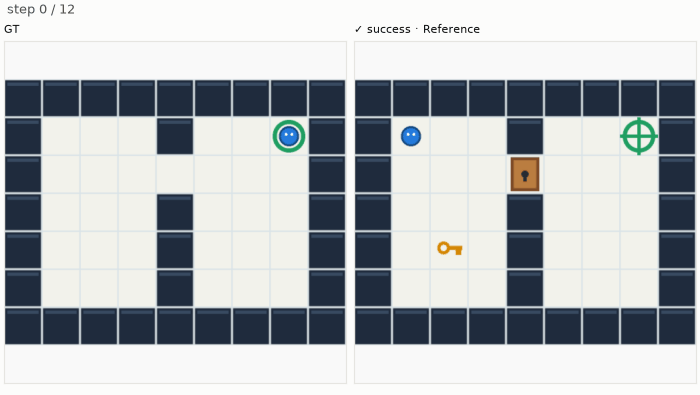

Static preview of the recorded episode. Rerun this cell to view the animation.

### LeWM

**KeyDoor-v0 · LeWM** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 29.1 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 30.2192 |
| Persistence | 0.1234 |

Latent standard deviation: **0.813**. Latent errors are comparable within this model; their scale differs between models.

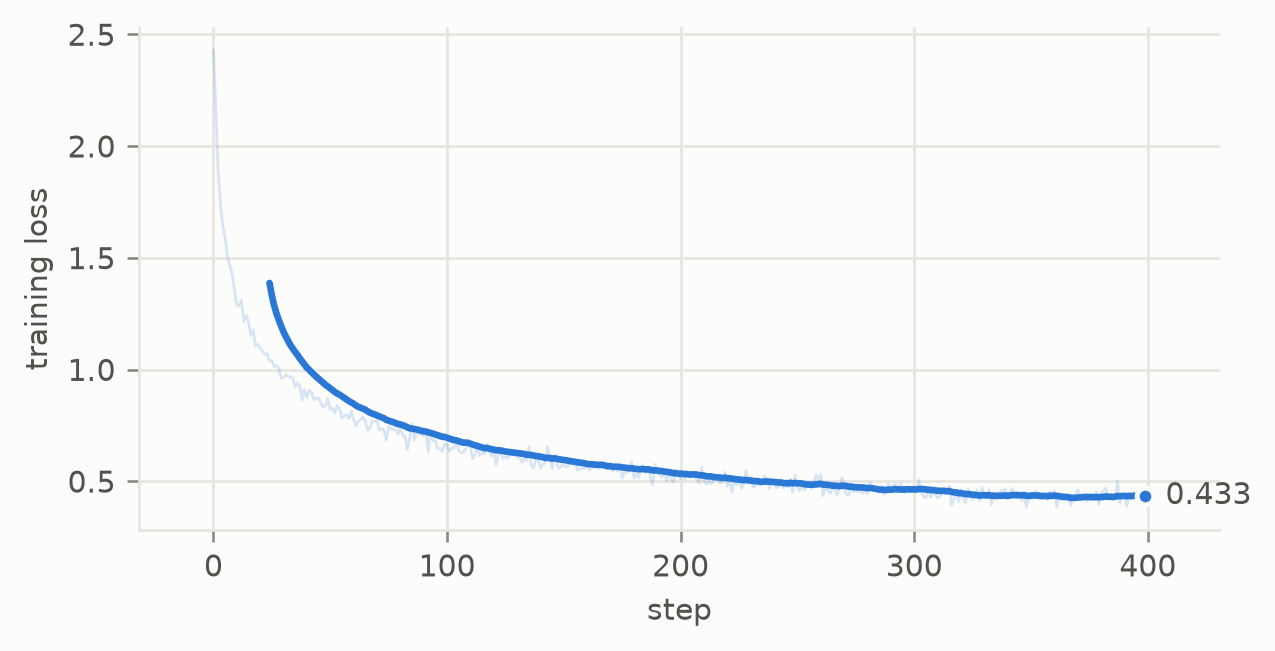

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 49%] | 60.0 | 9.500 |
| random | 0% [0%, 49%] | 60.0 | 9.250 |

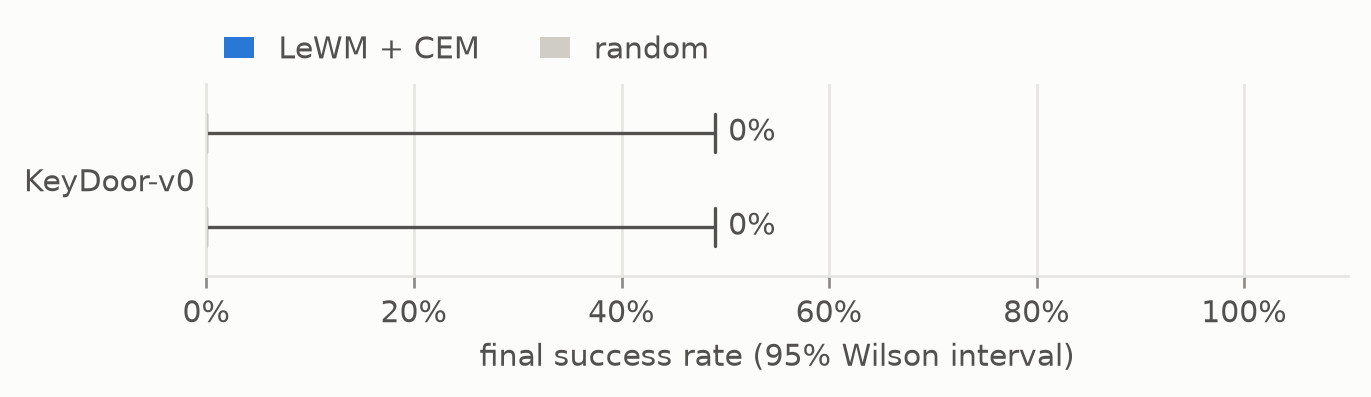

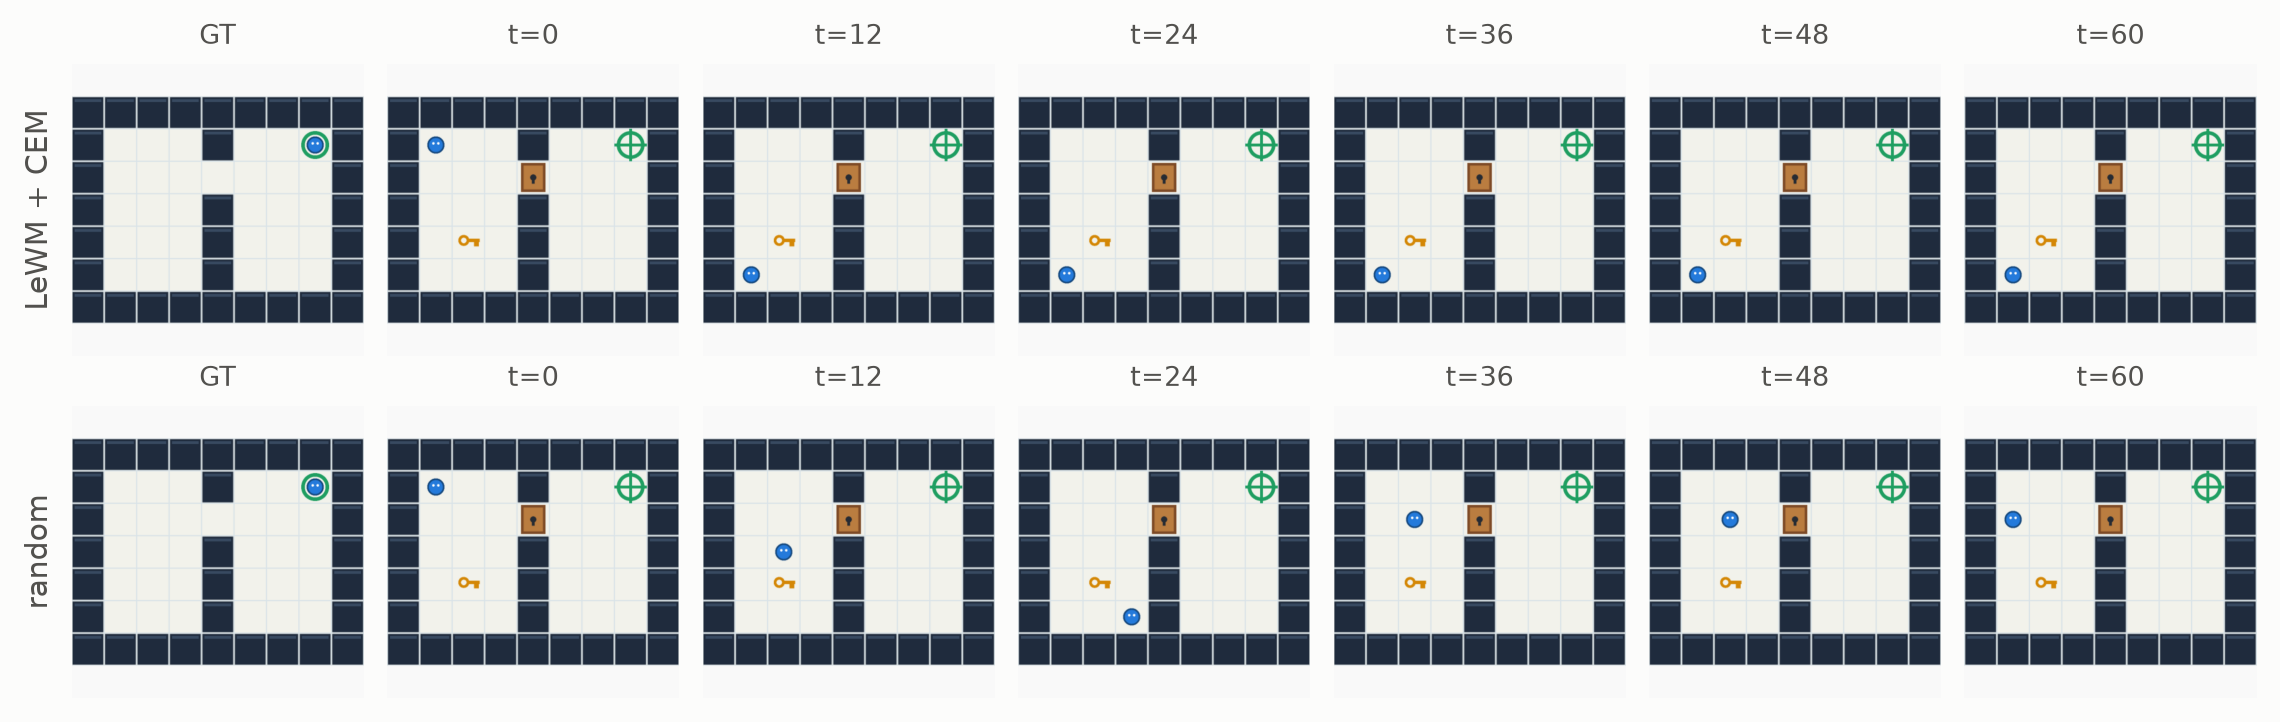

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

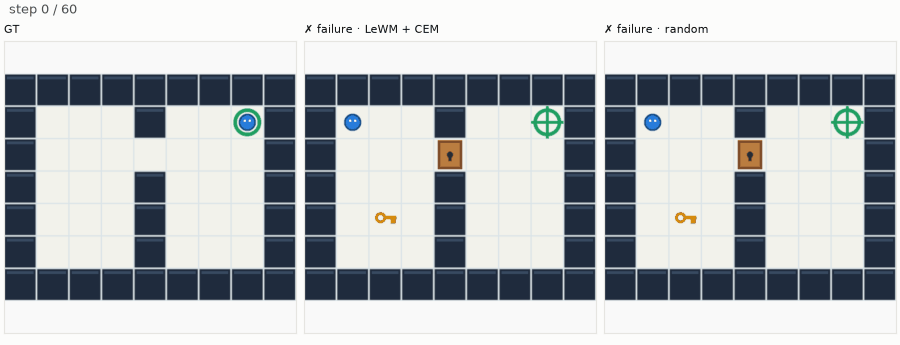

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/custom_model_three_envs/20261015T115501476827Z/KeyDoor-v0/LeWM/20261015T115704282393Z-10d9f24b


### ResidualWorldModel

**KeyDoor-v0 · ResidualWorldModel** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 26.7 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| ResidualWorldModel | 0.0001 |
| Persistence | 0.0000 |

Latent standard deviation: **0.005**. Latent errors are comparable within this model; their scale differs between models.

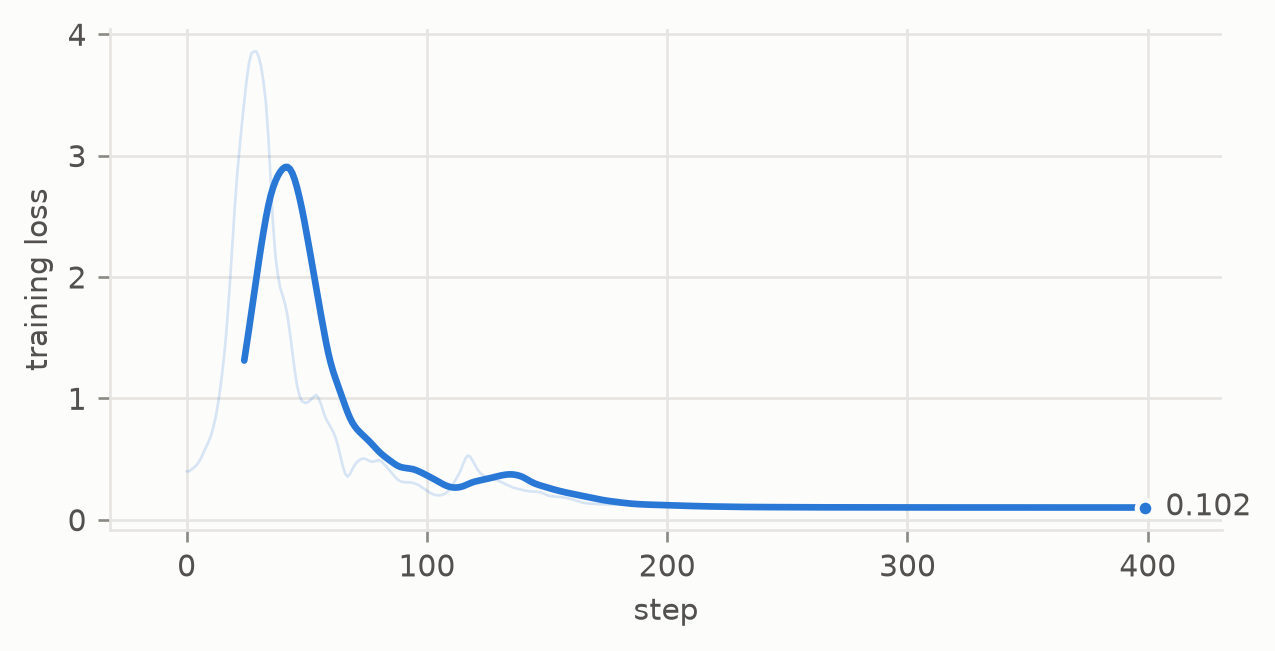

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| ResidualWorldModel + CEM | 0% [0%, 49%] | 60.0 | 6.500 |
| random | 0% [0%, 49%] | 60.0 | 9.250 |

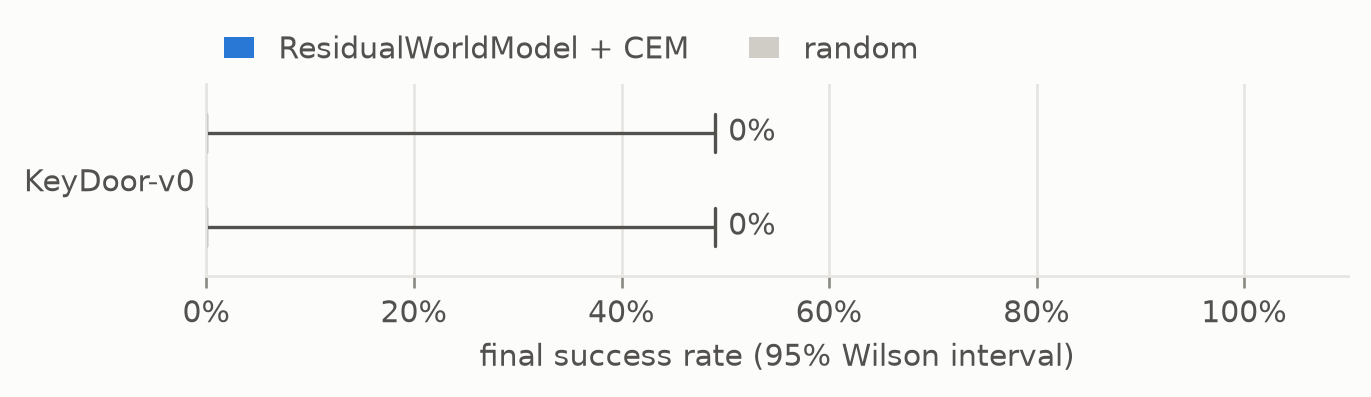

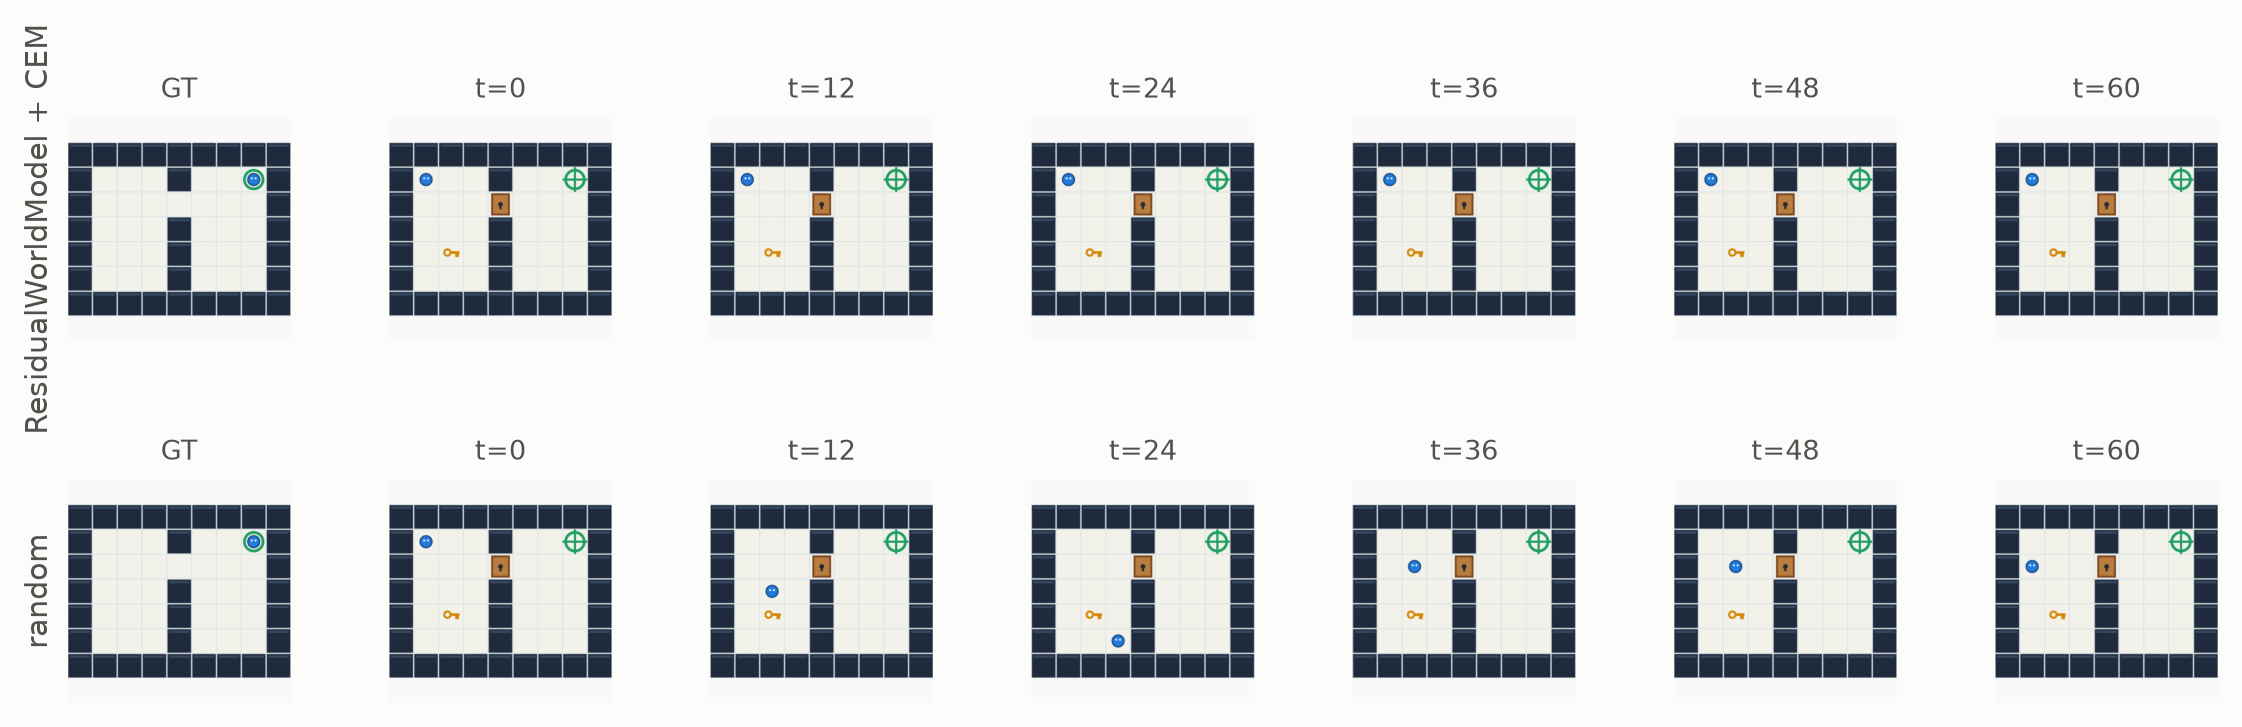

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

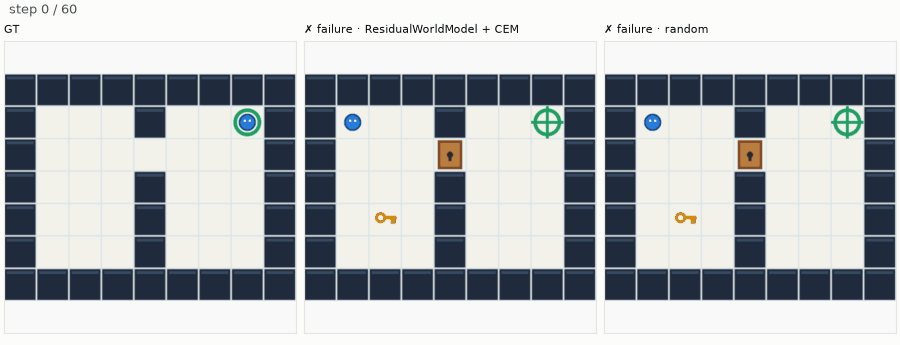

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/custom_model_three_envs/20261015T115501476827Z/KeyDoor-v0/ResidualWorldModel/20261015T115745960627Z-e072756a


In [5]:
with KeyDoor(quality="high") as world:
    results.extend(compare_models(world))

## 3. Sokoban

Push the crate onto its target. Pushes can be irreversible, so a planner must account for the crate's future accessibility. **GT** shows a valid solved configuration.

**Sokoban-v0 · torch** — Push a box to a target without trapping it. 2 normalized action components in [-1, 1].

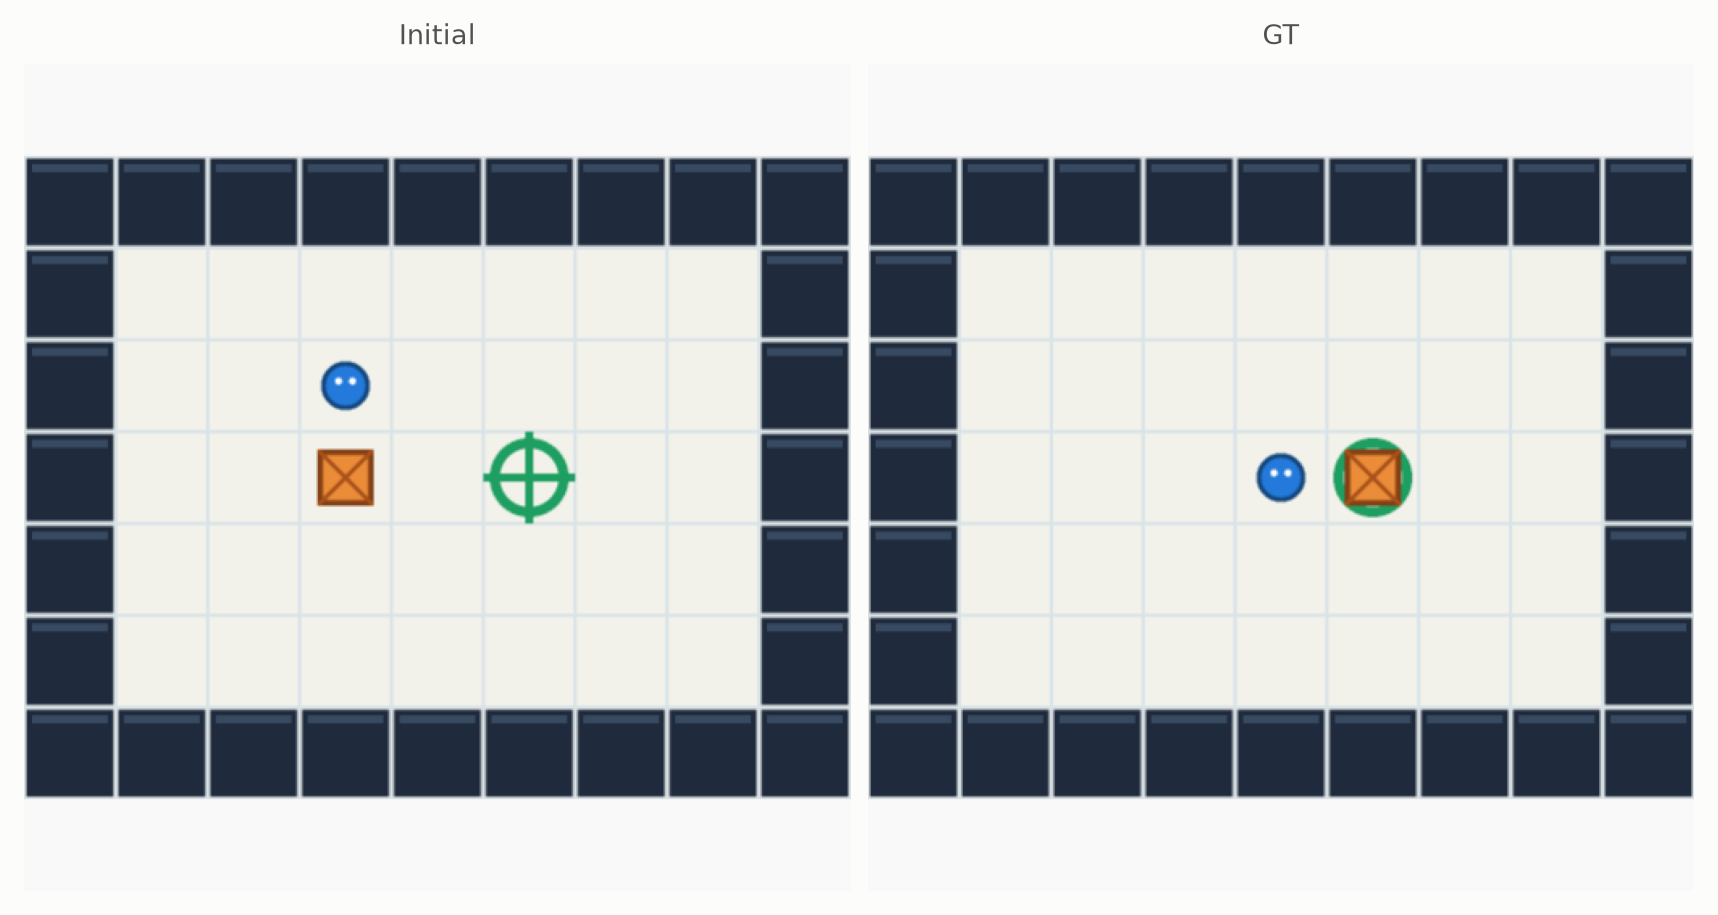

**GT reference solution** — verified environment actions, not a model rollout.

**Sokoban-v0** — verified reference episode; separate from model evaluation.

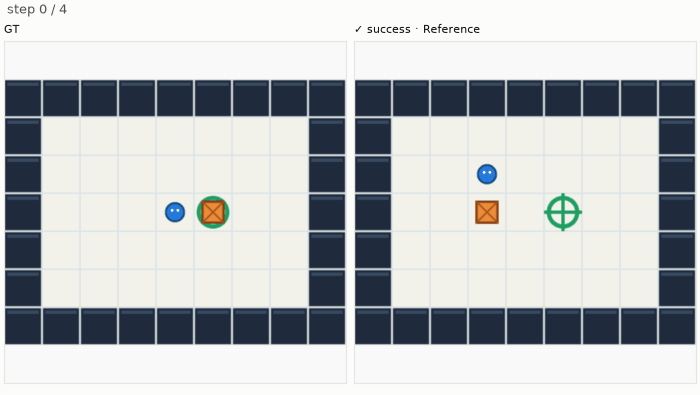

Static preview of the recorded episode. Rerun this cell to view the animation.

### LeWM

**Sokoban-v0 · LeWM** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 27.8 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| LeWM | 1362.8201 |
| Persistence | 0.0059 |

Latent standard deviation: **0.710**. Latent errors are comparable within this model; their scale differs between models.

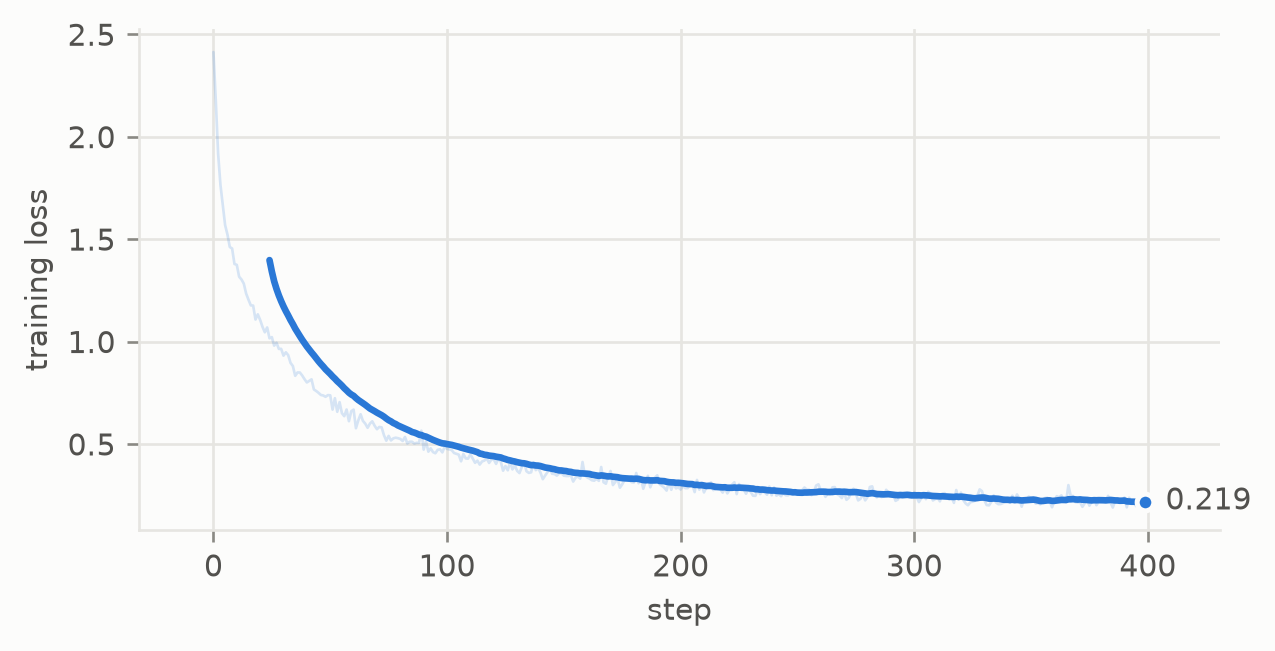

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| LeWM + CEM | 0% [0%, 49%] | 60.0 | 2.250 |
| random | 25% [5%, 70%] | 50.2 | 2.750 |

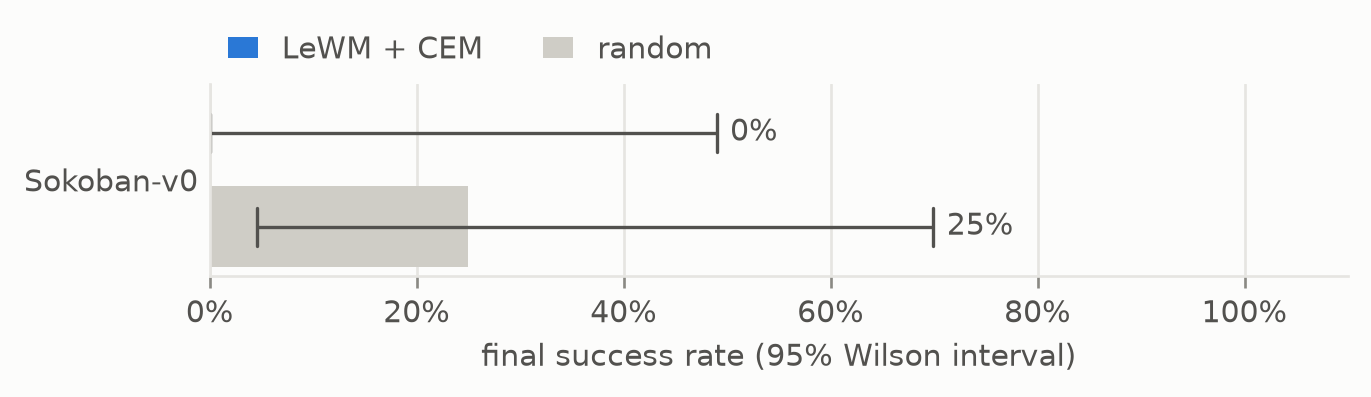

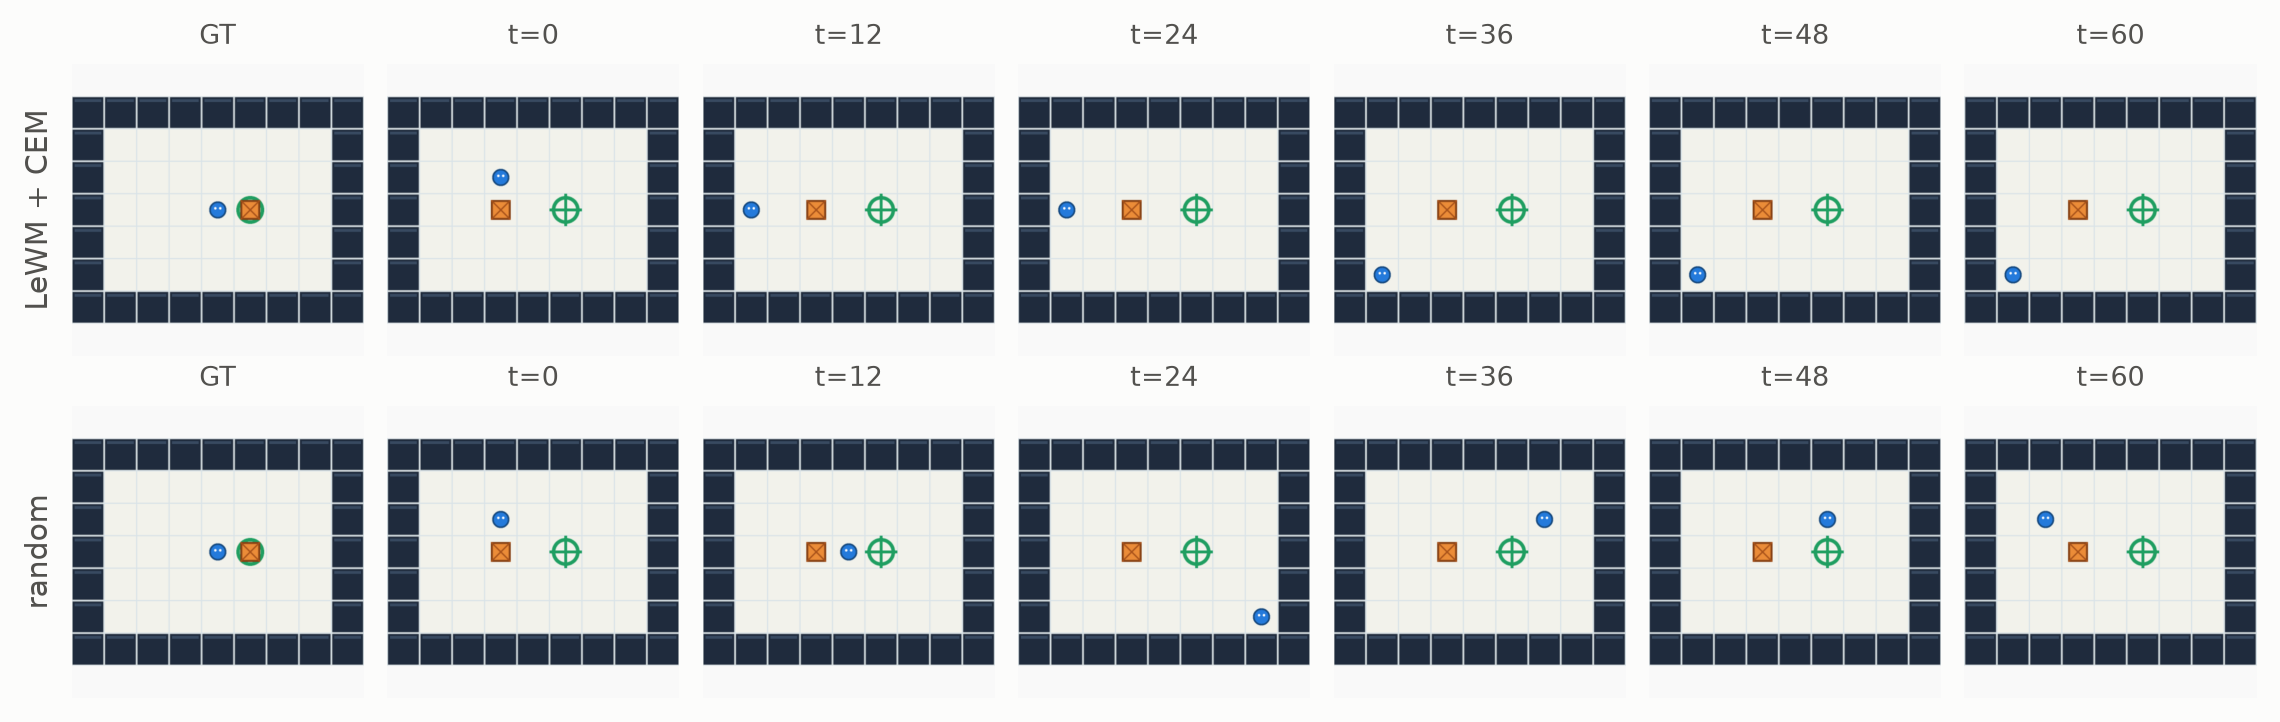

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

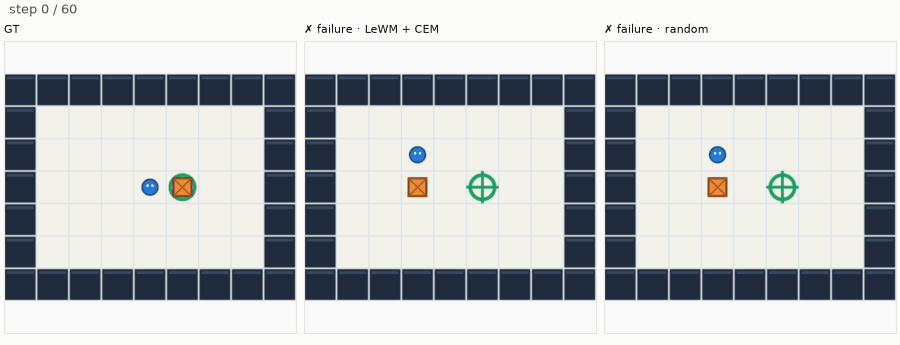

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/custom_model_three_envs/20261015T115501476827Z/Sokoban-v0/LeWM/20261015T115829987733Z-d9440639


### ResidualWorldModel

**Sokoban-v0 · ResidualWorldModel** — pixels observations, seed 7, 400 updates, 2,048 training / 512 held-out pairs. cuda; 27.2 s.

| Prediction method | Held-out latent MSE ↓ |
|---|---:|
| ResidualWorldModel | 0.0074 |
| Persistence | 0.0000 |

Latent standard deviation: **0.003**. Latent errors are comparable within this model; their scale differs between models.

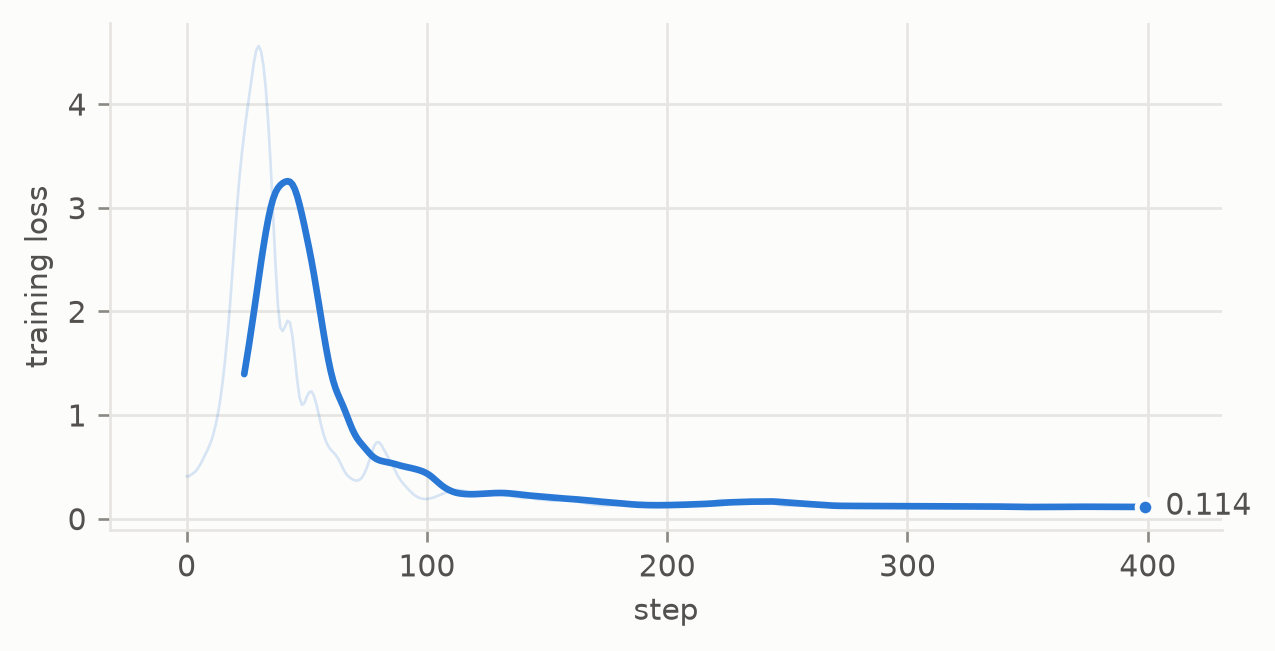

| Policy | Success | Steps | Final distance ↓ |
|---|---:|---:|---:|
| ResidualWorldModel + CEM | 0% [0%, 49%] | 60.0 | 4.000 |
| random | 25% [5%, 70%] | 50.2 | 2.750 |

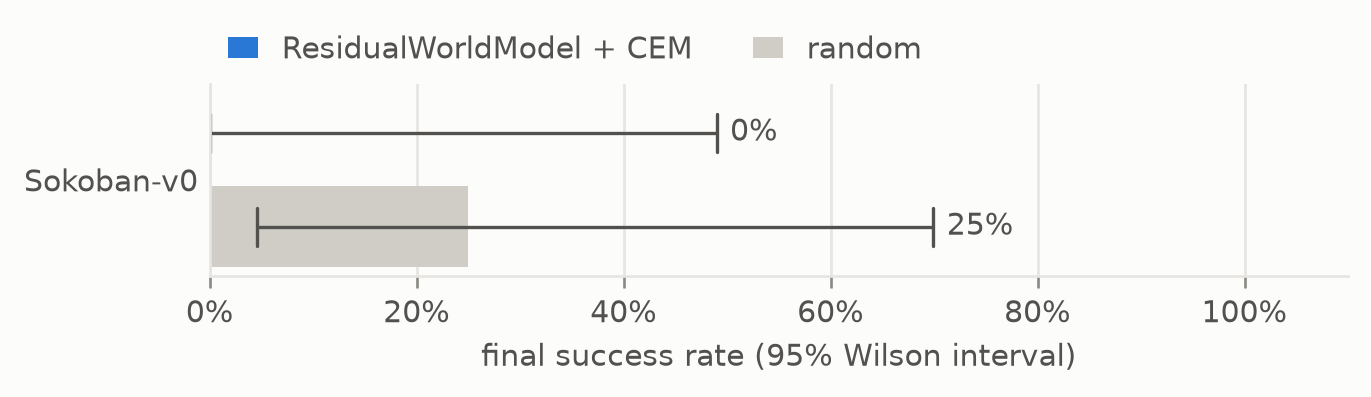

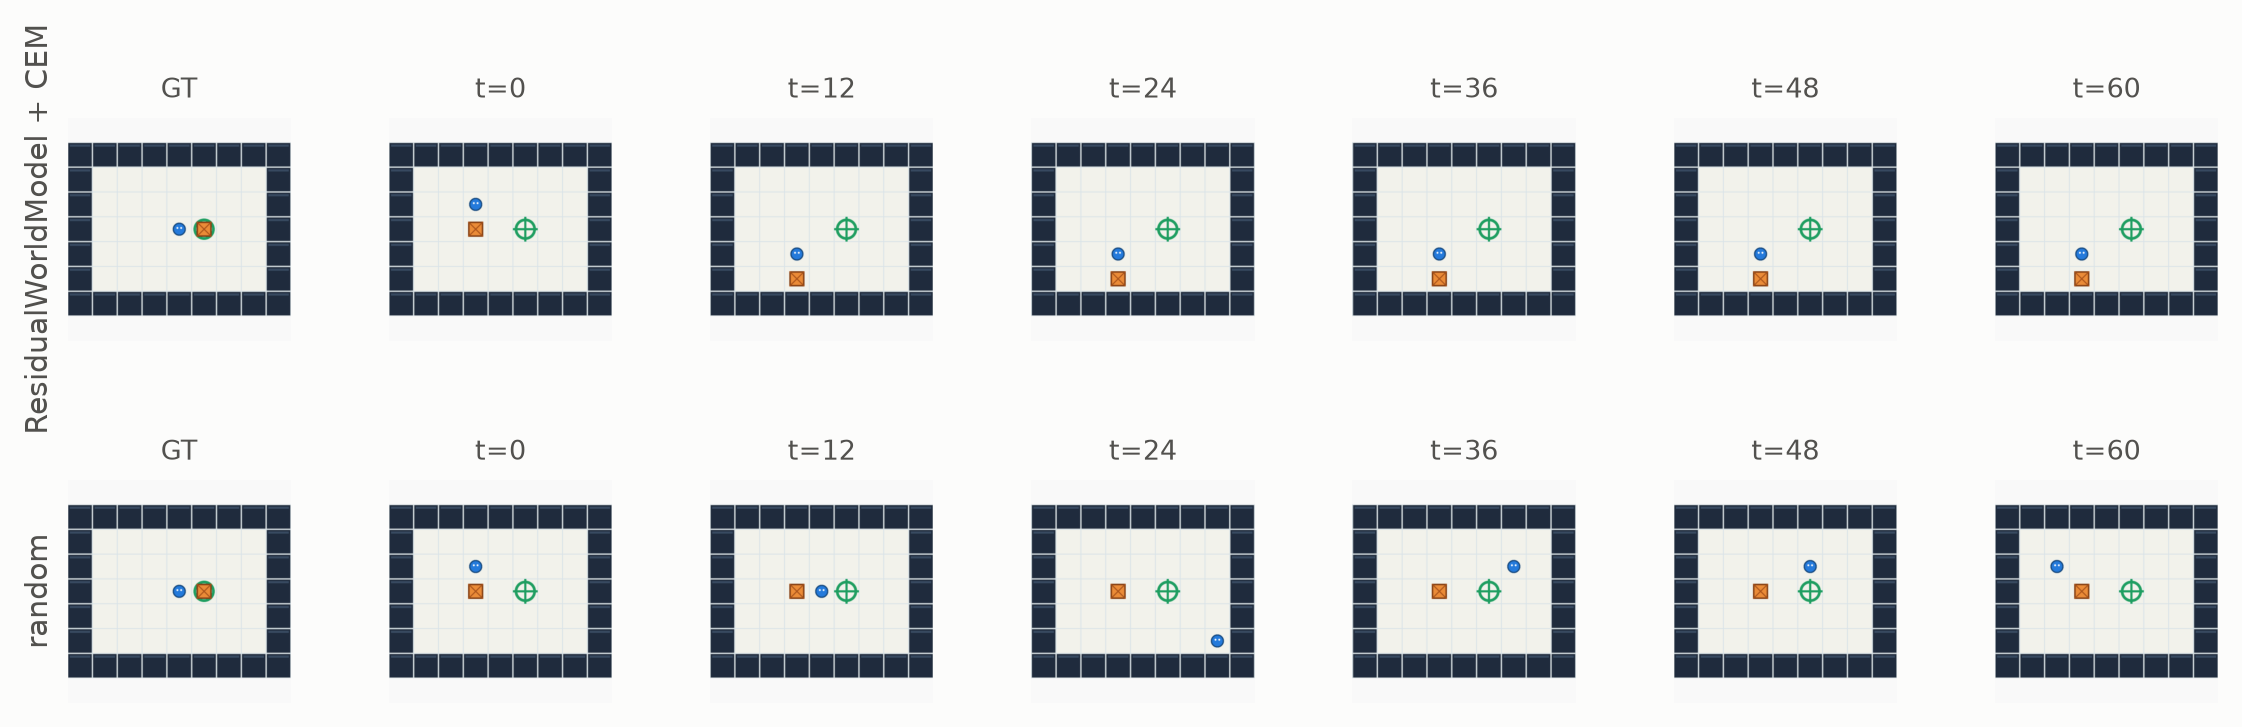

First evaluation seed shown; both policies start from the same state. All seeds are scored above.

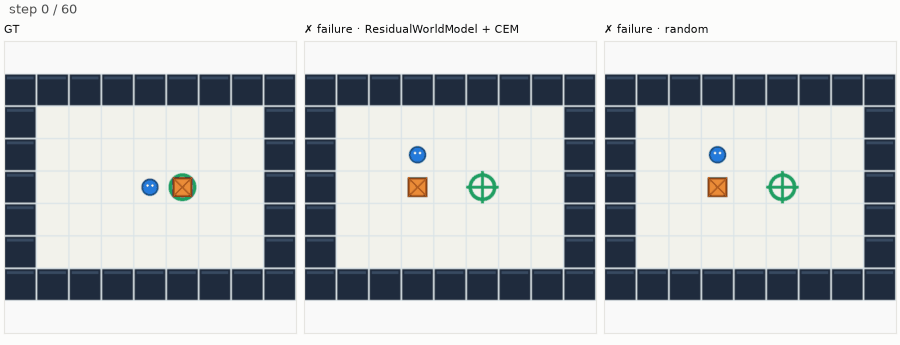

Static preview of the recorded episode. Rerun this cell to view the animation.

Saved run: runs/custom_model_three_envs/20261015T115501476827Z/Sokoban-v0/ResidualWorldModel/20261015T115911708274Z-2febdcc8


In [6]:
with Sokoban(quality="high") as world:
    results.extend(compare_models(world))

## Comparison and saved results

Compare success within each environment. Error bars are 95% Wilson intervals over the four evaluation episodes. Random actions use the same seeds in both model runs; the chart shows that control once per environment. The CSV preserves both runs independently and includes provenance hashes; it does not pool different models or tasks.

| Environment | Model | Success | Mean return | Final distance ↓ |
|---|---|---:|---:|---:|
| Maze-v0 | LeWM | 0% [0%, 49%] | -0.600 | 5.500 |
| Maze-v0 | ResidualWorldModel | 0% [0%, 49%] | -0.600 | 10.000 |
| KeyDoor-v0 | LeWM | 0% [0%, 49%] | -0.600 | 9.500 |
| KeyDoor-v0 | ResidualWorldModel | 0% [0%, 49%] | -0.600 | 6.500 |
| Sokoban-v0 | LeWM | 0% [0%, 49%] | -0.600 | 2.250 |
| Sokoban-v0 | ResidualWorldModel | 0% [0%, 49%] | -0.600 | 4.000 |

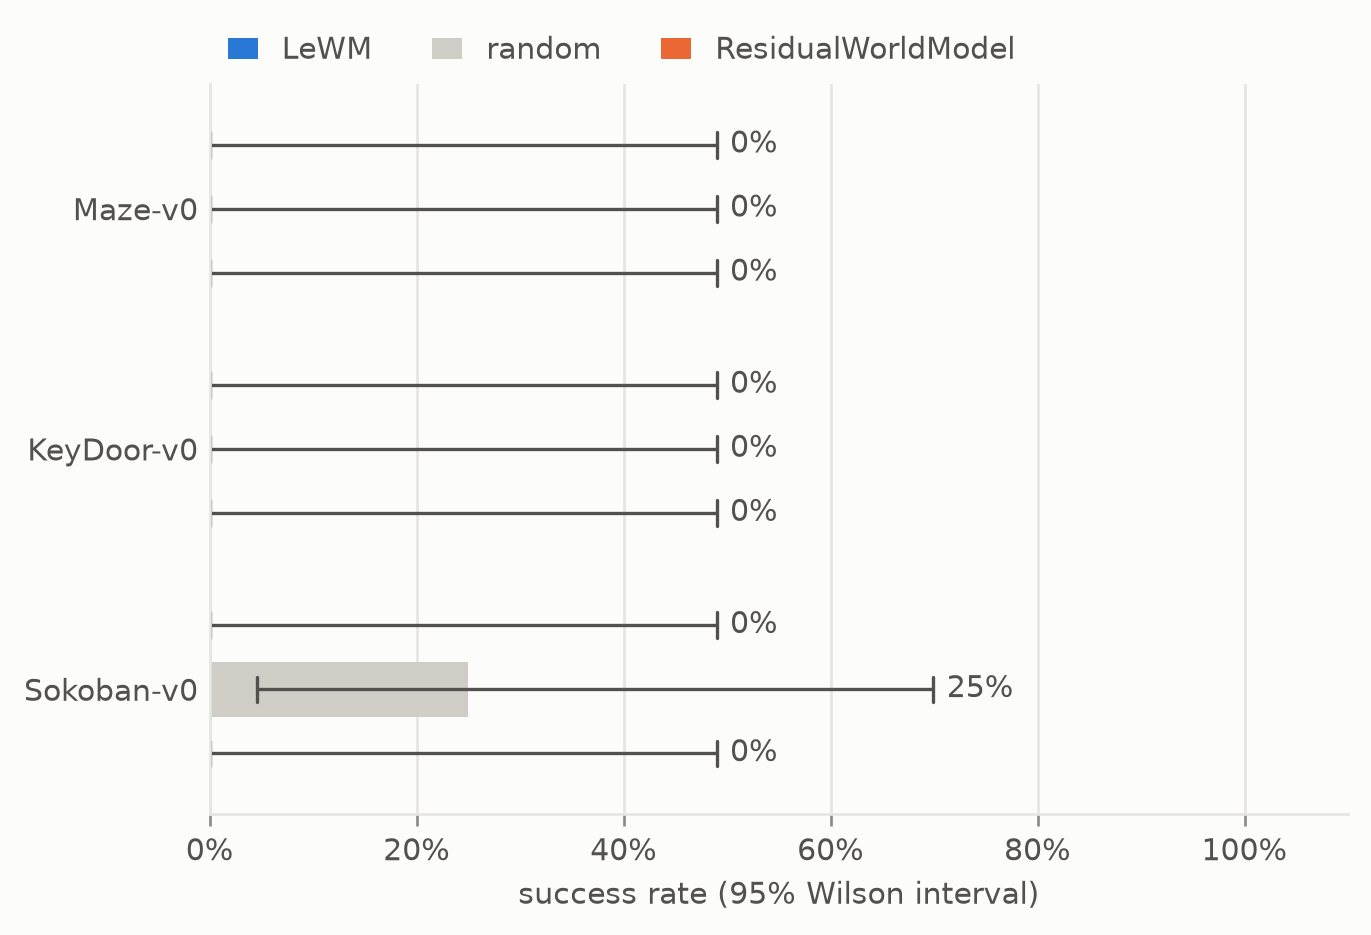

Saved 6 runs / 12 policy rows: runs/custom_model_three_envs/20261015T115501476827Z/summary.csv


In [7]:
rows = write_summary(OUTPUT_DIR, OUTPUT_DIR / "summary.csv")
table = [
    "| Environment | Model | Success | Mean return | Final distance ↓ |",
    "|---|---|---:|---:|---:|",
]
groups = {}
for result in results:
    scores = result["evaluation"][result["planner_policy"]]
    rate = metrics.success_rate(torch.tensor(scores["successes"]).bool())
    distance = sum(scores["final_distances"]) / len(scores["final_distances"])
    table.append(f"| {result['env_id']} | {result['model']} | {rate} | {scores['mean_return']:.3f} | {distance:.3f} |")
    group = groups.setdefault(result["env_id"], {})
    group[result["model"]] = rate
    random_scores = result["evaluation"]["random"]
    group["random"] = metrics.success_rate(torch.tensor(random_scores["successes"]).bool())

display(Markdown("\n".join(table)))
display(plots.bars(groups, xlabel="success rate (95% Wilson interval)", baseline="random"))
print(f"Saved {len(results)} runs / {len(rows)} policy rows: {OUTPUT_DIR / 'summary.csv'}")

To add another environment, construct it and pass it to `compare_models`. To change the model, replace `model_factory` or add another factory to `MODEL_FACTORIES`; the experiment and result format stay the same. To revisit a saved run without training, use `show_results(load_run(run_dir))` from `torch_world.benchmarks`.